In [1]:
import numpy as np
from scipy.special import comb, jv

def Vnm(r, f, n, m):
    L_max = 35  # For good convergence, L_max ~ 3 times defocus parameter.
                # for most practical cases L_max=35 is more than sufficient.
    u = np.zeros_like(f)
    u_temp = 0
    q = 1/2 * (n + m)
    p = 1/2 * (n - m)
    
    for l in range(1, L_max + 1):
        u_p = 0
        for j in range(0, int(p) + 1):
            if (p - j) < l:
                u_p += (-1) ** p * (m + l + 2 * j) * comb(m + j + l - 1, l - 1) * comb(j + l - 1, l - 1) * comb(l - 1, p - j) / comb(q + l + j, l) * jv(m + l + 2 * j, r) / (l * r ** l)
        u_temp += (-2j * f) ** (l - 1) * u_p
    
    u_scalar = 2 * np.exp(1j * f) * u_temp
    return u_scalar

/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/matplotlib/contour.py:1454: ComplexWarning: Casting complex values to real discards the imaginary part
  self.zmax = float(z.max())
/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/matplotlib/contour.py:1455: ComplexWarning: Casting complex values to real discards the imaginary part
  self.zmin = float(z.min())
/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/numpy/ma/core.py:2820: ComplexWarning: Casting complex values to real discards the imaginary part
  _data = np.array(data, dtype=dtype, copy=copy,


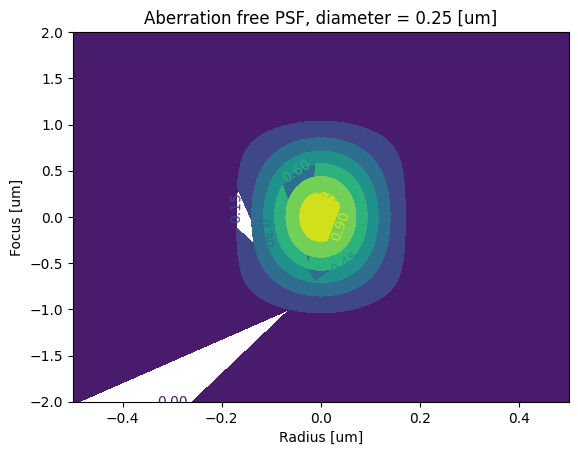

In [53]:
import numpy as np
import matplotlib.pyplot as plt

# This example calculates the through-focus intensity point-spread function for a
# lambda=0.20 micron, NA=0.50, optical system. In addition the finite pinhole size
# of 0.25 micron is taken into account. It is assumed that the optical
# system has no aberrations. The maximum intensity is normalized to 1.
#
# the setting are easily changed by modifing the parameters in this routine.

na = 0.50        # the numerical aperture
diam = 0.25      # diameter in microns
lambda_ = 0.200  # wavelength in microns
eps = 0.00001    # a small offset epsilon, to avoid dividing by zero

radius = diam / 2
ap = 2 * np.pi * (na / lambda_) * radius
d = 1 / 8 * ap**2 + 1 / 384 * ap**4 + 1 / 10240 * ap**6  # optimal d.

scale_z = lambda_ / (2 * np.pi) * 1 / (1 - np.sqrt(1 - na**2))  # scaling factor for defocus

r_list = np.arange(-0.5, 0.5+0.0125, 0.0125)
f_list = np.arange(-2, 2+0.05, 0.05)
r, f = np.meshgrid((r_list + eps) * 2 * np.pi * na / lambda_, f_list / scale_z)

f = f + 1j * d  # by using a complex defocus parameter, the finite diameter is taken into account.

m = 0
n = 0  # aberration free, so only the m=n=0 term is needed.
field = Vnm(r, f, n, m)  # Assuming Vnm is defined elsewhere
intensity = field * np.conj(field)  # intensity is the square of the field.
intensity = intensity / np.max(intensity)  # max intensity normalized to 1.

"""plt.gca().set_fontsize(14)  # plotting routine
"""
contour = plt.contourf(r_list, f_list, intensity)
plt.clabel(contour)
plt.title(f'Aberration free PSF, diameter = {diam} [um]')
plt.xlabel('Radius [um]')
plt.ylabel('Focus [um]')
plt.show()

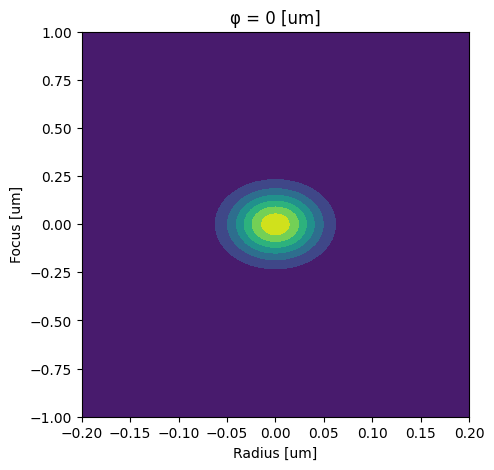

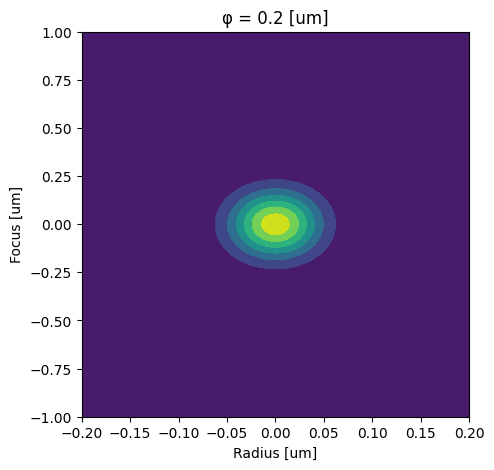

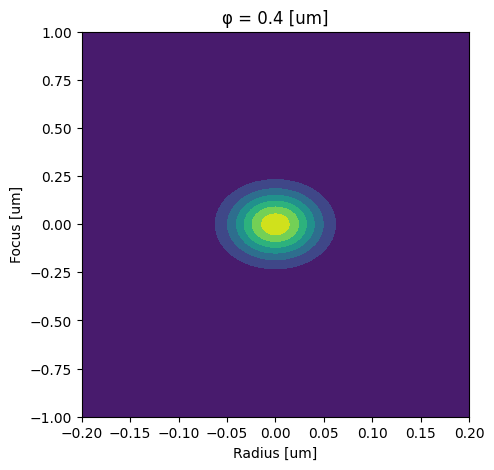

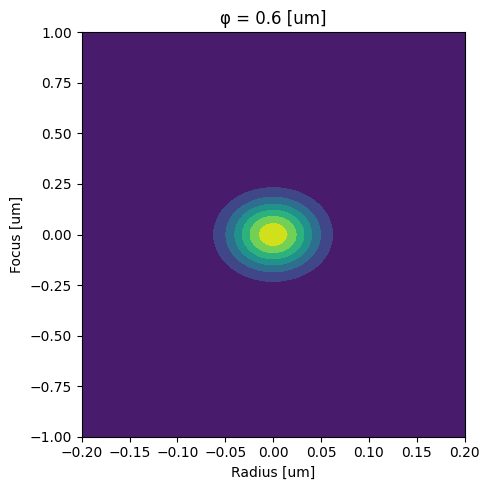

In [100]:
import numpy as np
import matplotlib.pyplot as plt

# This example calculates the through-focus intensity point-spread function for a
# lambda=0.20 micron, NA=0.50, optical system. In addition the finite pinhole size
# of is varied from 0 ... 0.60 micron. It is assumed that the optical
# system has no aberrations. The maximum intensity is normalized to 1 for
# all plots
#
# The setting are easily changed by modifying the parameters in this routine.

diameter_list = [0, 0.2, 0.4, 0.6]  # the list of three diameters.

na = 0.50  # the numerical aperture
lambda_ = 0.200  # wavelength in microns
eps = 0.00001  # a small offset epsilon, to avoid dividing by zero

scale_z = lambda_ / (2 * np.pi) * 1 / (1 - np.sqrt(1 - na**2))  # scaling factor for defocus
r_list = np.arange(-0.2, 0.2+0.005, 0.005)
f_list = np.arange(-1, 1+0.025, 0.025)
r, f = np.meshgrid((r_list + eps) * 2 * np.pi * na / lambda_, f_list / scale_z)

for teller in range(len(diameter_list)):
    diam = diameter_list[teller]  # diameter in microns
    radius = diam / 2
    ap = 2 * np.pi * (na / lambda_) * radius
    d = 1 / 8 * ap**2 + 1 / 384 * ap**4 + 1 / 10240 * ap**6  # optimal d.

    f = f + 1j * d  # by using a complex defocus parameter, the finite diameter is taken into account.

    m = 0
    n = 0  # aberration free, so only the m=n=0 term is needed.
    field = Vnm(r, f, n, m)
    intensity = field * np.conj(field)  # intensity is the square of the field.
    intensity = intensity / np.max(intensity)  # max intensity normalized to 1.

    fig, axes = plt.subplots(1, figsize=(5,5))  # plotting routine
    plt.contourf(r_list, f_list, intensity)
    plt.title(f'φ = {diam} [um]')
    plt.xlabel('Radius [um]')
    plt.ylabel('Focus [um]')
    #plt.axis('square')

plt.tight_layout()
plt.show()

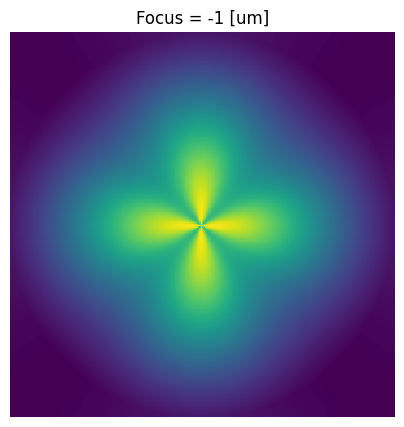

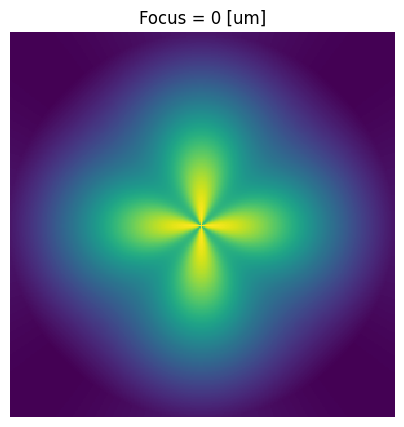

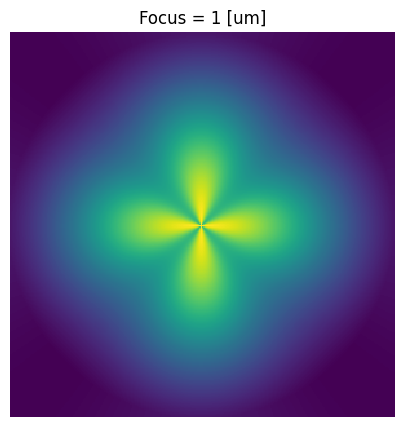

In [131]:
import numpy as np
import matplotlib.pyplot as plt

# This example calculates the through-focus intensity point-spread function for a
# lambda=0.20 micron, NA=0.50, optical system. In addition the finite pinhole size
# of 0.25 micron is taken into account. It is assumed that the optical
# system suffers from astigmatism aberration (m=2; n=2).
#
# The PSF for three focus values are shown.
#
# All setting are easily changed by modifying the parameters in this routine.

m = 2
n = 2

Z = 0.1

na = 0.50        # the numerical aperture
diam = 0.5      # diameter in microns
lambda_ = 0.500  # wavelength in microns
eps = 0.00001    # a small offset epsilon, to avoid dividing by zero

radius = diam / 2
ap = 2 * np.pi * (na / lambda_) * radius
d = 1 / 8 * ap**2 + 1 / 384 * ap**4 + 1 / 10240 * ap**6  # optimal d.

scale_z = lambda_ / (2 * np.pi) * 1 / (1 - np.sqrt(1 - na**2))  # scaling factor for defocus

r_list = np.arange(0, 0.15, 0.001)
f_list = np.arange(-1, 2, 1)
r, f = np.meshgrid((r_list + eps) * 2 * np.pi * na / lambda_, f_list / scale_z)

f = f + 1j * d  # by using a complex defocus parameter, the finite diameter is taken into account.

x, y = np.meshgrid(np.concatenate([-r_list[::-1][1:], r_list]), np.concatenate([-r_list[::-1][1:], r_list]))
phi = np.angle(x + 1j * y)

u_0 = np.zeros_like(x)
u_aber = np.zeros_like(x)
u_0 = Vnm(r, f, 0, 0)
u_aber = Vnm(r, f, n, m)

for foc in range(len(f_list)):
    u_0xy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_0[foc, :])
    u_0xy = u_0xy.reshape(x.shape)
    u_aberxy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_aber[foc, :])
    u_aberxy = 1j**(m + 1) * 2 * np.pi * Z * u_aberxy.reshape(x.shape) * np.cos(m * phi)
    field = u_0xy + u_aberxy
    intensity = np.real(field * np.conj(field))
    
    fig, axs = plt.subplots(1, figsize=(5,5))
    plt.pcolor(x, y, intensity)
    plt.axis('square')
    plt.axis('off')
    plt.title(f'Focus = {f_list[foc]} [um]')

plt.show()

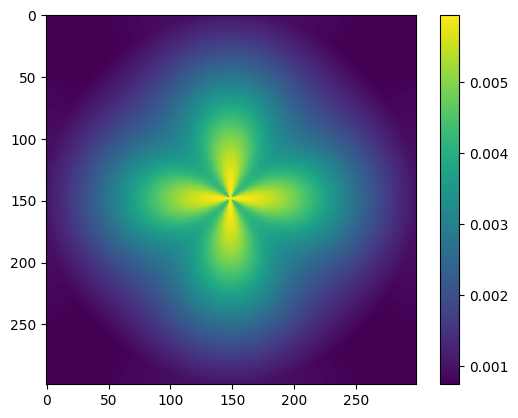

In [132]:
u_0xy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_0[0, :])
u_0xy = u_0xy.reshape(x.shape)
u_aberxy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_aber[0, :])
u_aberxy = 1j**(m + 1) * 2 * np.pi * Z * u_aberxy.reshape(x.shape) * np.cos(m * phi)
field = u_0xy + u_aberxy
intensity0 = np.real(field * np.conj(field))

plt.imshow(intensity)
plt.colorbar()

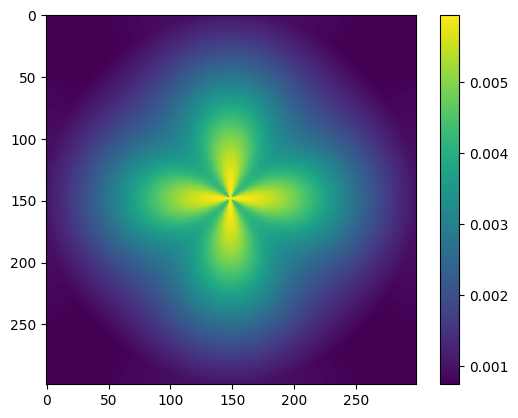

In [133]:
u_0xy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_0[-1, :])
u_0xy = u_0xy.reshape(x.shape)
u_aberxy = np.interp(np.sqrt(x.flatten()**2 + y.flatten()**2), r_list, u_aber[-1, :])
u_aberxy = 1j**(m + 1) * 2 * np.pi * Z * u_aberxy.reshape(x.shape) * np.cos(m * phi)
field = u_0xy + u_aberxy
intensity1 = np.real(field * np.conj(field))

plt.imshow(intensity)
plt.colorbar()

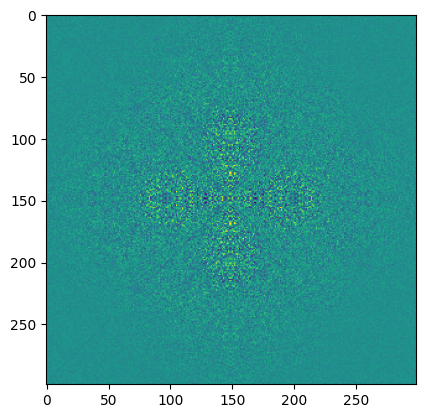

In [135]:
plt.imshow(intensity0-intensity1)

In [8]:
import argparse
import math
import sys

import matplotlib.pyplot as p
import numpy as np
from numpy.linalg import norm
from numpy.random import normal

import enzpy.enz as enz
from psf_plot import PSFPlot
"""Example about using enzpy.

Plot the point-spread function that corresponds to a given complex-valued
Zernike analysis of the generalised pupil function.

References
----------
 .. [A2015] Jacopo Antonello and Michel Verhaegen, "Modal-based phase retrieval
    for adaptive optics," J. Opt. Soc. Am. A 32, 1160-1170 (2015) . `url
    <http://dx.doi.org/10.1364/JOSAA.32.001160>`__.

"""


# handy object for plotting the PSF
class BetaPlot:
    def __init__(self, args):
        psfplot = PSFPlot(wavelength=args.wavelength,
                          aperture_radius=args.aperture_radius,
                          focal_length=args.focal_length,
                          pixel_size=args.pixel_size,
                          image_width=args.image_width,
                          image_height=args.image_height,
                          fspace=np.linspace(args.defocus_interval[0],
                                             args.defocus_interval[1],
                                             args.defocus_step),
                          n_beta=args.n_beta)
        self.psfplot = psfplot

    def plot_beta(self, beta):
        psfplot = self.psfplot

        # pick the PSF and Zernike objects
        cpsf = psfplot.cpsf
        czern = cpsf.czern

        nn, mm = 2, math.ceil(psfplot.fspace.size // 2)
        p.figure(1)
        p.clf()

        for fi, f in enumerate(psfplot.fspace):
            p.subplot(nn, mm, fi + 1)

            # plot the PSF
            psfplot.plot_beta_f(beta, fi)
            p.colorbar()

            # defocus in rad
            p.title('d={:.1f}'.format(enz.get_defocus(f)))

        p.figure(2)
        p.clf()

        # Zernike coefficients of alpha_true and alpha_hat
        p.subplot(3, 1, 1)
        p.plot(range(1, czern.nk + 1), beta.real, marker='o')
        p.ylabel('[rad]')
        p.legend([r'$\beta$ real'])

        p.subplot(3, 1, 2)
        p.plot(range(1, czern.nk + 1), beta.imag, marker='o')
        p.ylabel('[rad]')
        p.legend([r'$\beta$ imag'])

        p.subplot(3, 1, 3)
        p.bar(range(1, czern.nk + 1), np.abs(beta))
        p.xlabel('Noll index')
        p.ylabel('[rad]')
        p.legend([r'$|\beta|$'])


if __name__ == '__main__':

    parser = argparse.ArgumentParser(
        description='''Plot the point-spread function that corresponds to a
        given complex-valued Zernike analysis of the generalised pupil
        function.''',
        epilog='''
        Random beta coefficients: ./beta_abs.py --random.
        Astigmatism, 1 rms rad: ./beta_abs.py --nm 2 2 --rm 1.0.
        Trefoil: ./beta_abs.py --noll 9.
        ''',
        formatter_class=argparse.ArgumentDefaultsHelpFormatter)

    parser.add_argument('--wavelength',
                        type=float,
                        default=632.8e-9,
                        help='Wavelength [m].')
    parser.add_argument('--aperture-radius',
                        type=float,
                        default=0.002,
                        help='Aperture radius [m].')
    parser.add_argument('--focal-length',
                        type=float,
                        default=500e-3,
                        help='Focal length [m].')
    parser.add_argument('--image-width',
                        type=int,
                        default=75,
                        help='Image width [#pixels].')
    parser.add_argument('--image-height',
                        type=int,
                        default=151,
                        help='Image height [#pixels].')
    parser.add_argument('--pixel-size',
                        type=float,
                        default=7.4e-6,
                        help='Pixel size [m].')
    parser.add_argument(
        '--n-beta',
        type=int,
        default=4,
        metavar='N_BETA',
        help='Maximum radial order of the complex-valued Zernike polynomials.')
    parser.add_argument('--defocus-interval',
                        type=float,
                        nargs=2,
                        default=[-3.0, 2.0],
                        metavar=('MIN', 'MAX'),
                        help='Range of the defocus parameter.')
    parser.add_argument('--defocus-step',
                        type=int,
                        default=6,
                        metavar='STEP',
                        help='Step size of the defocus parameter.')
    parser.add_argument('--nm',
                        type=int,
                        nargs=2,
                        default=[-1, -1],
                        metavar=('N', 'M'),
                        help='Specify Zernike polynomial N_n^m using n and m.')
    parser.add_argument(
        '--noll',
        type=int,
        default=-1,
        metavar='N_k',
        help="Specify Zernike polynomial N_k using Noll's index k.")
    parser.add_argument('--rms',
                        type=float,
                        default=1.0,
                        help='Rms of the beta aberration.')
    parser.add_argument('--random',
                        action='store_true',
                        help='Make a random beta aberration.')

    args = parser.parse_args()

    # plotter
    betaplot = BetaPlot(args)

    # get the complex-valued Zernike polynomials object
    czern = betaplot.psfplot.cpsf.czern

    # beta (diffraction-limited), N_beta = czern.nk
    beta = np.zeros(czern.nk, np.complex)
    beta[0] = 1.0

    # nm to linear index conversion
    nmlist = list(zip(czern.ntab, czern.mtab))

    # set a beta coefficient using the (n, m) indeces
    if args.nm[0] != -1 and args.nm[0] != -1:
        try:
            k = nmlist.index(tuple(args.nm))
            beta[k] = args.rms
        except BaseException:
            print('Cannot find indeces ' + str(args.nm))
            print('Possible [n, m] indeces are:')
            print(nmlist)
            sys.exit(1)

    # set a beta coefficient using Noll's single index
    if args.noll != -1:
        try:
            beta[args.noll - 1] = args.rms
        except BaseException:
            print('Cannot set the required Noll index k.')
            print('Index k must be between 1 and ' + str(beta.size))
            sys.exit(1)

    # set the beta coefficients randomly
    if args.random:
        beta = normal(size=beta.size) + 1j * normal(size=beta.size)
        beta = (args.rms / norm(beta)) * beta  # sort of
        beta[0] = 1

    # plot results
    betaplot.plot_beta(beta)
    p.show()

ModuleNotFoundError: No module named 'psf_plot'

In [15]:
def _is_odd(integer):
    """Helper for testing if an integer is odd by bitwise & with 1."""
    return integer & 1
    
def schwiegerling_basis(n, m, pn, pm, npix=100, rho=None, theta=None, **kwargs):
    """Return the Schwiegerling PSF basis function."""

    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1.) / 2.) / (2.)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    aperture = (rho <= 20)

    if m - pm == 0:
        result = -1**((n-pn)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho)

    elif _is_odd(m - pm) == 1:
        result = 2* -1**((n-pn+1)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho) * np.sin((m-pm) * theta)

    else:
        result = 2* -1**((n-pn)/2) * jv(n+1, 2*np.pi*rho) * (1/rho) * jv(pn+1, 2*np.pi*rho) * (1/rho) * np.cos((m-pm) * theta)

    return result

In [17]:
schwiegerling_basis(n=0,m=0,pn=0,pm=0)

NameError: name 'jv' is not defined

In [12]:
npix=100
x = (np.arange(npix, dtype=np.float64) - (npix - 1.) / 2.) / (2.)